# Benchmark de Chatbots (LLMs): Evaluación de Calidad

Este notebook analiza los resultados obtenidos por los modelos de lenguaje en `chats.ipynb`, guardados en `resultados_chatbots.csv`.

Se evalúan las respuestas con las métricas de la **Fase 3** del README:
- **Corrección:** escala 0 a 2 (2 correcta, 1 incompleta o imprecisa, 0 incorrecta).
- **Fidelidad:** porcentaje de respuestas sin datos inventados.
- **Abstención:** si responde 'No aparece en el documento' cuando la respuesta no está en el contexto.
- **Formato e idioma:** en español y con cita a la fuente o artículo.

### 1. Cargar librerías y datos
Cargamos las librerías necesarias y el archivo con los resultados generados por los chatbots.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Cargar datos del benchmark de chatbots
archivo_csv = "resultados_chatbots.csv"
datos = pd.read_csv(archivo_csv)

print(f"Total de preguntas evaluadas: {len(datos)}")
display(datos[["pregunta", "contexto_top3"]].head(2))

Total de preguntas evaluadas: 274


,pregunta,contexto_top3
0,¿Qué ocurre con el contrato de trabajo si el d...,5. La calificación por la autoridad judicial d...
1,¿Qué tipo de acción se podrá reclamar en confl...,Contra las decisiones a que se refiere el pres...


### 2. Modelos evaluados y comprobación de contexto
Definimos los modelos con su tamaño y cuantización, y comprobamos si el fragmento relevante está en los 3 fragmentos recuperados (top 3) por el embedding.

In [2]:
# Modelos del benchmark con tamaño y cuantización
modelos = {
    "NVIDIA-Nemotron-3.5-Bolt-E4B-GGUF": {"nombre": "Nemotron-3.5-4B", "tamano": "4B", "cuantizacion": "Q4_K_XL"},
    "K2-Horizon-3.7B-GGUF": {"nombre": "K2-Horizon-3.7B", "tamano": "3.7B", "cuantizacion": "Q6_K"},
    "Ling-3.0-tiny-GGUF": {"nombre": "Ling-3.0-tiny", "tamano": "1.5B", "cuantizacion": "Q5_K_M"},
    "Ornith-1.5-9B-GGUF": {"nombre": "Ornith-1.5-9B", "tamano": "9B", "cuantizacion": "Q4_K_M"}
}

# Comprobar si el texto relevante está en el contexto recuperado (top 3)
tiene_respuesta = datos.apply(lambda fila: fila["texto"][:50] in fila["contexto_top3"], axis=1)
con_respuesta = tiene_respuesta.sum()
sin_respuesta = len(datos) - con_respuesta

print(f"Preguntas con respuesta en el contexto: {con_respuesta}")
print(f"Preguntas sin respuesta en el contexto: {sin_respuesta}")

Preguntas con respuesta en el contexto: 258
Preguntas sin respuesta en el contexto: 16


### 3. Cálculo de la Tabla B (Calidad de LLMs según el README)
Calculamos la corrección media (0 a 2), porcentaje de respuestas fieles, abstenciones correctas, falsas abstenciones y formato e idioma promediando las evaluaciones de los 4 evaluadores.

In [3]:
jueces = list(modelos.keys())
filas_tabla = []

for id_modelo, info in modelos.items():
    lista_correccion = []
    lista_fidelidad = []
    lista_formato = []

    # Extraer puntuaciones de todos los evaluadores
    for juez in jueces:
        columna = f"evaluacion_{id_modelo}_por_{juez}"
        for celda in datos[columna]:
            evaluacion = json.loads(celda)
            lista_correccion.append(int(evaluacion.get("correccion", 0)))
            lista_fidelidad.append(1 if evaluacion.get("fidelidad") == "si" else 0)
            lista_formato.append(1 if evaluacion.get("formato_e_idioma") == "si" else 0)

    # Contar abstenciones directas en las respuestas del modelo
    dice_no_aparece = datos[id_modelo].str.contains("no aparece", case=False, na=False)
    abstenciones_correctas = (dice_no_aparece & (~tiene_respuesta)).sum()
    falsas_abstenciones = (dice_no_aparece & tiene_respuesta).sum()

    filas_tabla.append({
        "Modelo": info["nombre"],
        "Tamaño": info["tamano"],
        "Cuantización": info["cuantizacion"],
        "Corrección media (0–2)": round(sum(lista_correccion) / len(lista_correccion), 2),
        "Respuestas fieles (%)": round(sum(lista_fidelidad) / len(lista_fidelidad) * 100, 1),
        "Abstención correcta (%)": round((abstenciones_correctas / sin_respuesta) * 100, 1),
        "Falsas abstenciones": falsas_abstenciones,
        "Formato e idioma (%)": round(sum(lista_formato) / len(lista_formato) * 100, 1)
    })

# Crear DataFrame y ordenar según el criterio del README
tabla_calidad = pd.DataFrame(filas_tabla)
tabla_calidad = tabla_calidad.sort_values(
    by=["Respuestas fieles (%)", "Corrección media (0–2)"],
    ascending=[False, False]
).reset_index(drop=True)

# Guardar resultados en CSV para trazabilidad
tabla_calidad.to_csv("tabla_b_calidad_chatbots.csv", index=False)

print("=" * 80)
print("Tabla B. LLMs: calidad (Estatuto de los Trabajadores - BOE)")
print("=" * 80)
display(tabla_calidad)

Tabla B. LLMs: calidad (Estatuto de los Trabajadores - BOE)


,Modelo,Tamaño,Cuantización,Corrección media (0–2),Respuestas fieles (%),Abstención correcta (%),Falsas abstenciones,Formato e idioma (%)
0,Nemotron-3.5-4B,4B,Q4_K_XL,1.94,99.2,43.8,17,96.4
1,K2-Horizon-3.7B,3.7B,Q6_K,1.94,98.7,37.5,33,97.4
2,Ornith-1.5-9B,9B,Q4_K_M,1.94,98.6,37.5,28,97.7
3,Ling-3.0-tiny,1.5B,Q5_K_M,1.87,96.4,37.5,28,95.3


### 4. Matriz de notas entre evaluadores
Puntuación media de corrección otorgada por cada juez a cada modelo para verificar el consenso entre evaluadores.

In [4]:
# Puntuación media de corrección que da cada juez a cada modelo
matriz = {}

for id_modelo, info_modelo in modelos.items():
    nombre_modelo = info_modelo["nombre"]
    matriz[nombre_modelo] = {}
    for id_juez, info_juez in modelos.items():
        nombre_juez = info_juez["nombre"]
        columna = f"evaluacion_{id_modelo}_por_{id_juez}"
        notas = [json.loads(c).get("correccion", 0) for c in datos[columna]]
        matriz[nombre_modelo][nombre_juez] = round(sum(notas) / len(notas), 2)

tabla_matriz = pd.DataFrame(matriz).T
tabla_matriz.columns.name = "Juez"
display(tabla_matriz)

Juez,Nemotron-3.5-4B,K2-Horizon-3.7B,Ling-3.0-tiny,Ornith-1.5-9B
Nemotron-3.5-4B,1.88,1.97,1.99,1.92
K2-Horizon-3.7B,1.86,1.96,1.99,1.95
Ling-3.0-tiny,1.79,1.87,1.96,1.86
Ornith-1.5-9B,1.88,1.94,2.00,1.95


### 5. Gráfico comparativo de métricas
Visualizamos las métricas clave de calidad (Fidelidad, Formato e idioma y Corrección normalizada sobre 100).

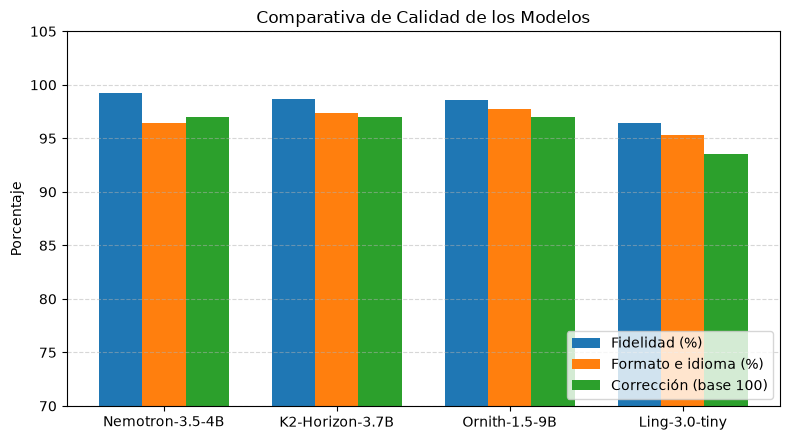

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))

nombres = tabla_calidad["Modelo"]
posiciones = range(len(nombres))
ancho = 0.25

ax.bar([p - ancho for p in posiciones], tabla_calidad["Respuestas fieles (%)"], width=ancho, label="Fidelidad (%)")
ax.bar(posiciones, tabla_calidad["Formato e idioma (%)"], width=ancho, label="Formato e idioma (%)")
ax.bar([p + ancho for p in posiciones], tabla_calidad["Corrección media (0–2)"] * 50, width=ancho, label="Corrección (base 100)")

ax.set_xticks(posiciones)
ax.set_xticklabels(nombres)
ax.set_ylim(70, 105)
ax.set_ylabel("Porcentaje")
ax.set_title("Comparativa de Calidad de los Modelos")
ax.legend(loc="lower right")
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 6. Revisión manual de respuestas
Muestra de respuestas generadas tal como salieron para contrastar el criterio del evaluador automático con la revisión humana.

In [6]:
# Mostrar ejemplos de respuestas para contrastar con la evaluación automática
for i in range(5):
    print(f"--- Pregunta {i + 1} ---")
    print(f"Pregunta: {datos.at[i, 'pregunta']}\n")
    for id_m, info_m in modelos.items():
        nombre = info_m["nombre"]
        print(f"[{nombre}]: {datos.at[i, id_m]}\n")
    print("=" * 60)

--- Pregunta 1 ---
Pregunta: ¿Qué ocurre con el contrato de trabajo si el despido es procedente convalidado?

[Nemotron-3.5-4B]: convalidará la extinción del contrato de trabajo que con aquel se produjo, sin derecho a indemnización ni a salarios de tramitación.

[K2-Horizon-3.7B]: El despido procedente convalidará la extinción del contrato de trabajo que con aquel se produjo, sin derecho a indemnización ni a salarios de tramitación.

[Ling-3.0-tiny]: Se concluye la extinción del contrato de trabajo, sin derecho a indemnización ni a salarios de tramitación.

[Ornith-1.5-9B]: El despido procedente convalidará la extinción del contrato de trabajo que con aquel se produjo, sin derecho a indemnización ni a salarios de tramitación.

--- Pregunta 2 ---
Pregunta: ¿Qué tipo de acción se podrá reclamar en conflicto colectivo contra las decisiones a que se refiere el presente apartado?

[Nemotron-3.5-4B]: Se podrá reclamar en conflicto colectivo cuando la decisión empresarial afecte a un número d

### 7. Conclusiones y elección final
Siguiendo las pautas de la Fase 4 del README ("elegir el modelo más pequeño y barato que cumple los umbrales de calidad"):

1. **Cumplimiento de calidad:**
   - Todos los modelos tienen alta fidelidad (> 96%) y adecuado formato en español (> 95%).
   - **Nemotron-3.5-4B** obtiene la mayor fidelidad (99.2%), iguala la máxima corrección media (1.94) y tiene el menor número de falsas abstenciones (17 frente a 28-33 de los demás).

2. **Recomendación para el Escenario 1 (BOE):**
   - **`unsloth/NVIDIA-Nemotron-3.5-Bolt-E4B-GGUF`** (4B, Q4_K_XL).
   - Rinde al mismo nivel o superior al modelo de 9B (Ornith), requiriendo la mitad de parámetros y menor consumo.

3. **Plan B (con límite de 8 GB de VRAM):**
   - Nemotron-3.5-4B cabe holgadamente en 8 GB de VRAM (~4.8 GB de modelo, dejando espacio para el contexto y el embedding).
   - Si se busca la máxima velocidad o un consumo mínimo, **Ling-3.0-tiny** (1.5B, Q5_K_M) es la alternativa más rápida, asumiendo una ligera caída en fidelidad (96.4%).